# Como um modelo aprende a responder instruções

Vamos acompanhar **o mesmo mini-GPT antes e depois do ajuste**: primeiro ele lê textos; depois aprende com exemplos de pedidos e respostas.

| Termo | O que muda |
|---|---|
| Pré-treino | Começamos com pesos aleatórios e prevemos os próximos tokens de textos. |
| Pré-treino continuado | Partimos de pesos já treinados e continuamos esse objetivo em outros textos. |
| SFT | Ajustamos pesos já treinados usando demonstrações de entradas e saídas desejadas. |
| Instruction tuning | Usamos instruções de diferentes tarefas e suas respostas para ensinar o modelo a atender pedidos; é uma aplicação de SFT. |

Aqui as tarefas são restritas: responder sobre capital, língua e continente. O formato de chat organiza os exemplos; ele não substitui o treinamento.



In [ ]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # matrizes pequenas: 1 thread é mais rápido e mais reprodutível
import copy
import math
import re
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

TEAL, AMBER, INK, RED, CINZA = "#17897B", "#E08A3C", "#0F1C2E", "#C0392B", "#8494A6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Bibliotecas prontas.")

Bibliotecas prontas.


## 1. Os dados que controlamos

O mundo didático tem **42 países com três atributos**, 10 países mencionados sem a capital e 6 reservados para uma extensão de pré-treino continuado.

Cada fato aparece em várias frases. Acrescentamos listas de quiz sem respostas para criar um caso em que continuar uma pergunta significa escrever outra pergunta. Esse comportamento do modelo base foi favorecido pelo corpus.

**Observe:** há documentos para treino e validação, mas eles podem repetir os mesmos fatos e até o mesmo texto. Essa validação acompanha a previsão nesse mundo pequeno; não testa conhecimento de países novos.

In [ ]:
#@title O mundo: países, frases e o gerador de documentos (execute; leitura opcional)
# pais, "de", "em", artigo, capital, lingua mais falada, continente
PAISES = [
    ("Brasil", "do", "no", "O", "Brasília", "português", "América do Sul"),
    ("Argentina", "da", "na", "A", "Buenos Aires", "espanhol", "América do Sul"),
    ("Chile", "do", "no", "O", "Santiago", "espanhol", "América do Sul"),
    ("Peru", "do", "no", "O", "Lima", "espanhol", "América do Sul"),
    ("Colômbia", "da", "na", "A", "Bogotá", "espanhol", "América do Sul"),
    ("Venezuela", "da", "na", "A", "Caracas", "espanhol", "América do Sul"),
    ("Uruguai", "do", "no", "O", "Montevidéu", "espanhol", "América do Sul"),
    ("Equador", "do", "no", "O", "Quito", "espanhol", "América do Sul"),
    ("México", "do", "no", "O", "Cidade do México", "espanhol", "América do Norte"),
    ("Canadá", "do", "no", "O", "Ottawa", "inglês", "América do Norte"),
    ("Portugal", "de", "em", "", "Lisboa", "português", "Europa"),
    ("Espanha", "da", "na", "A", "Madri", "espanhol", "Europa"),
    ("França", "da", "na", "A", "Paris", "francês", "Europa"),
    ("Itália", "da", "na", "A", "Roma", "italiano", "Europa"),
    ("Alemanha", "da", "na", "A", "Berlim", "alemão", "Europa"),
    ("Grécia", "da", "na", "A", "Atenas", "grego", "Europa"),
    ("Polônia", "da", "na", "A", "Varsóvia", "polonês", "Europa"),
    ("Suécia", "da", "na", "A", "Estocolmo", "sueco", "Europa"),
    ("Noruega", "da", "na", "A", "Oslo", "norueguês", "Europa"),
    ("Finlândia", "da", "na", "A", "Helsinque", "finlandês", "Europa"),
    ("Dinamarca", "da", "na", "A", "Copenhague", "dinamarquês", "Europa"),
    ("Áustria", "da", "na", "A", "Viena", "alemão", "Europa"),
    ("Hungria", "da", "na", "A", "Budapeste", "húngaro", "Europa"),
    ("Romênia", "da", "na", "A", "Bucareste", "romeno", "Europa"),
    ("Croácia", "da", "na", "A", "Zagreb", "croata", "Europa"),
    ("Japão", "do", "no", "O", "Tóquio", "japonês", "Ásia"),
    ("China", "da", "na", "A", "Pequim", "chinês", "Ásia"),
    ("Coreia do Sul", "da", "na", "A", "Seul", "coreano", "Ásia"),
    ("Tailândia", "da", "na", "A", "Bangkok", "tailandês", "Ásia"),
    ("Vietnã", "do", "no", "O", "Hanói", "vietnamita", "Ásia"),
    ("Irã", "do", "no", "O", "Teerã", "persa", "Ásia"),
    ("Arábia Saudita", "da", "na", "A", "Riad", "árabe", "Ásia"),
    ("Índia", "da", "na", "A", "Nova Délhi", "hindi", "Ásia"),
    ("Iraque", "do", "no", "O", "Bagdá", "árabe", "Ásia"),
    ("Malásia", "da", "na", "A", "Kuala Lumpur", "malaio", "Ásia"),
    ("Angola", "de", "em", "", "Luanda", "português", "África"),
    ("Marrocos", "do", "no", "O", "Rabat", "árabe", "África"),
    ("Argélia", "da", "na", "A", "Argel", "árabe", "África"),
    ("Quênia", "do", "no", "O", "Nairóbi", "suaíli", "África"),
    ("Tunísia", "da", "na", "A", "Túnis", "árabe", "África"),
    ("Austrália", "da", "na", "A", "Camberra", "inglês", "Oceania"),
    ("Nova Zelândia", "da", "na", "A", "Wellington", "inglês", "Oceania"),
]
# o corpus fala destes paises, mas nunca diz a capital deles
SEM_CAPITAL = [
    ("Mongólia", "da", "na", "A", None, "mongol", "Ásia"),
    ("Nepal", "do", "no", "O", None, "nepalês", "Ásia"),
    ("Islândia", "da", "na", "A", None, "islandês", "Europa"),
    ("Bolívia", "da", "na", "A", None, "espanhol", "América do Sul"),
    ("Tanzânia", "da", "na", "A", None, "suaíli", "África"),
    ("Eslováquia", "da", "na", "A", None, "eslovaco", "Europa"),
    ("Lituânia", "da", "na", "A", None, "lituano", "Europa"),
    ("Laos", "do", "no", "O", None, "laosiano", "Ásia"),
    ("Omã", "de", "em", "", None, "árabe", "Ásia"),
    ("Sudão", "do", "no", "O", None, "árabe", "África"),
]
# paises que so aparecem no pre-treino continuado (fora do corpus original)
NOVOS = [
    ("Bulgária", "da", "na", "A", "Sófia", "búlgaro", "Europa"),
    ("Sérvia", "da", "na", "A", "Belgrado", "sérvio", "Europa"),
    ("Albânia", "da", "na", "A", "Tirana", "albanês", "Europa"),
    ("Jordânia", "da", "na", "A", "Amã", "árabe", "Ásia"),
    ("Líbano", "do", "no", "O", "Beirute", "árabe", "Ásia"),
    ("Somália", "da", "na", "A", "Mogadíscio", "somali", "África"),
]
RELACOES = ("capital", "lingua", "continente")

# frases do texto de pre-treino: varias formas para o mesmo fato
FRASES = {
    "capital": ["A capital {de} {P} é {C}.", "{C} é a capital {de} {P}.",
                "{Art}{P} tem {C} como capital.", "{Art}{P} tem como capital {C}."],
    "lingua": ["{Em} {P}, fala-se {L}.", "A língua mais falada {de} {P} é o {L}.",
               "O {L} é a língua mais falada {de} {P}.", "A maioria das pessoas {em} {P} fala {L}."],
    "continente": ["{Art}{P} fica na {K}.", "{Art}{P} é um país da {K}.",
                   "Um dos países da {K} é {art}{P}.", "Na {K} fica {art}{P}."],
}
# pedidos: as formas 0-4 aparecem no ajuste; 5 e 6 ficam guardadas para teste
PERGUNTAS = {
    "capital": ["Qual é a capital {de} {P}?", "Qual a capital {de} {P}?",
                "Me diga a capital {de} {P}.", "Você sabe qual é a capital {de} {P}?",
                "{P}: qual é a capital?", "{P} tem qual capital?",
                "A capital {de} {P} é qual?"],
    "lingua": ["Qual é a língua mais falada {de} {P}?", "Que língua se fala {em} {P}?",
               "Me diga a língua mais falada {de} {P}.", "Você sabe que língua se fala {em} {P}?",
               "{P}: qual é a língua mais falada?", "{P} fala qual língua?",
               "A língua mais falada {de} {P} é qual?"],
    "continente": ["Em que continente fica {art}{P}?", "Qual é o continente {de} {P}?",
                   "Me diga o continente {de} {P}.", "Você sabe em que continente fica {art}{P}?",
                   "{P}: qual é o continente?", "{Art}{P} fica em qual continente?",
                   "O continente {de} {P} é qual?"],
}
RESPOSTA = {"capital": "A capital {de} {P} é {C}.", "lingua": "{Em} {P}, fala-se {L}.",
            "continente": "{Art}{P} fica na {K}."}
SEGUIMENTO = {"capital": "E a capital?", "lingua": "E a língua?", "continente": "E o continente?"}
NAO_SEI = "Não sei a capital {de} {P}."
SISTEMA = "Responda em uma frase."


def preencher(modelo, pais):
    nome, de, em, art, capital, lingua, continente = pais
    return modelo.format(P=nome, de=de, em=em, Em=em.capitalize(),
                         Art=art + " " if art else "", art=art.lower() + " " if art else "",
                         C=capital, L=lingua, K=continente)

def gerar_corpus(paises, semente=0, textos_por_pais=24, quizzes=240):
    """Documentos de pre-treino: verbetes curtos e listas de perguntas sem resposta."""
    rng = np.random.default_rng(semente)
    docs = []
    for pais in paises:
        rels = RELACOES if pais[4] else ("lingua", "continente")
        for _ in range(textos_por_pais):
            frases = [preencher(FRASES[r][rng.integers(4)], pais) for r in rels]
            rng.shuffle(frases)
            docs.append(" ".join(frases))
    for _ in range(quizzes):
        linhas = ["Quiz de geografia:"]
        for i in range(int(rng.integers(4, 8))):
            pais, r = paises[rng.integers(len(paises))], RELACOES[rng.integers(3)]
            linhas.append("%d. %s" % (i + 1, preencher(PERGUNTAS[r][rng.integers(2)], pais)))
        docs.append("\n".join(linhas))
    rng.shuffle(docs)
    return docs

docs = gerar_corpus(PAISES + SEM_CAPITAL)
docs_cpt = gerar_corpus(NOVOS, semente=5, quizzes=0)   # só para o exercício de pré-treino continuado
ordem = np.random.default_rng(42).permutation(len(docs))
n_val = len(docs) // 10
docs_val = [docs[i] for i in ordem[:n_val]]             # documentos inteiros reservados para validação
docs_treino = [docs[i] for i in ordem[n_val:]]
quizzes = [d for d in docs if d.startswith("Quiz")]

print(f"{len(docs)} documentos: {len(docs) - len(quizzes)} verbetes e {len(quizzes)} listas de quiz")
print(f"Treino: {len(docs_treino)} documentos | validação: {len(docs_val)}")
print("\nUm verbete:\n ", next(d for d in docs if not d.startswith("Quiz") and "Peru" in d))
print("\nUma lista de quiz:\n ", quizzes[0].replace("\n", "\n  "))

1488 documentos: 1248 verbetes e 240 listas de quiz
Treino: 1340 documentos | validação: 148

Um verbete:
  Um dos países da América do Sul é o Peru. A maioria das pessoas no Peru fala espanhol. O Peru tem Lima como capital.

Uma lista de quiz:
  Quiz de geografia:
  1. Qual a capital do Laos?
  2. Qual é o continente de Portugal?
  3. Qual a capital da Tunísia?
  4. Que língua se fala em Portugal?


### Tokens: como o texto entra no modelo

Cada palavra, pontuação ou quebra de linha vira um token e recebe um ID. O exemplo abaixo mostra a transformação. Os marcadores `endoftext`, `im_start`, `im_end` e `pad` também recebem IDs próprios.

**Simplificação:** o vocabulário inclui antecipadamente palavras dos pedidos, da validação e da extensão opcional. Incluir uma palavra no vocabulário não treina o fato correspondente, mas essa escolha usa informação sobre os textos futuros. Em um projeto real, normalmente reutilizamos o tokenizador do modelo pré-treinado.

In [ ]:
ESPECIAIS = ["<|endoftext|>", "<|im_start|>", "<|im_end|>", "<|pad|>"]
_PADRAO = re.compile(r"<\|[a-z_]+\|>|\n|\w+|[^\w\s]")


def quebrar(texto):
    """Um token por palavra, pontuação, quebra de linha ou token especial."""
    return _PADRAO.findall(texto)


def juntar(tokens):
    s = " ".join(tokens)
    s = re.sub(r" ?\n ?", "\n", s)
    s = re.sub(r" ([.,?:!])", r"\1", s).replace(" - ", "-")
    return s.replace("<|im_start|> ", "<|im_start|>").replace(" <|im_end|>", "<|im_end|>")


class Tokenizador:
    def __init__(self, textos):
        palavras = sorted({t for texto in textos for t in quebrar(texto)} - set(ESPECIAIS))
        self.vocab = ESPECIAIS + palavras
        self.id = {t: i for i, t in enumerate(self.vocab)}

    def codificar(self, texto):
        return [self.id[t] for t in quebrar(texto)]

    def decodificar(self, ids):
        return juntar([self.vocab[i] for i in ids])


def textos_do_mundo(*corpora):
    """Tudo o que o modelo poderá ler. Como num LLM real, o vocabulário é fixado antes do treino."""
    textos = [d for corpus in corpora for d in corpus]
    for pais in PAISES + SEM_CAPITAL + NOVOS:
        for r in RELACOES:
            textos += [preencher(f, pais) for f in PERGUNTAS[r]]
            if pais[4] is not None or r != "capital":
                textos.append(preencher(RESPOSTA[r], pais))
        textos.append(preencher(NAO_SEI, pais))
    return textos + list(SEGUIMENTO.values()) + [SISTEMA, "system user assistant :\n"]


tok = Tokenizador(textos_do_mundo(docs, docs_cpt))
EOT, PAD, FIM = tok.id["<|endoftext|>"], tok.id["<|pad|>"], tok.id["<|im_end|>"]

def para_ids(documentos):
    return np.array([i for d in documentos for i in tok.codificar(d) + [EOT]])

ids_treino, ids_val, ids_cpt = para_ids(docs_treino), para_ids(docs_val), para_ids(docs_cpt)
frase = "No Peru, fala-se espanhol."
print(f"Vocabulário: {len(tok.vocab)} tokens | texto de treino: {len(ids_treino)} tokens")
print("Tokens:", quebrar(frase))
print("IDs:   ", tok.codificar(frase))

Vocabulário: 220 tokens | texto de treino: 39797 tokens
Tokens: ['No', 'Peru', ',', 'fala', '-', 'se', 'espanhol', '.']
IDs:    [93, 105, 5, 165, 6, 201, 164, 7]


## 2. Criar o modelo base

Usamos um Transformer decoder pequeno: embeddings, duas camadas de atenção causal e MLPs. As 132 mil variáveis aprendidas serão os mesmos parâmetros ajustados no SFT. A matemática está na célula recolhida.

No **pré-treino**, `X` é uma janela de texto, `Y` é o próximo token em cada posição e `M` vale 1 para todos os alvos. Na função abaixo, acompanhe o lote, a perda e o gradiente e a atualização. O SFT reutilizará essa função.

**Observe o gráfico:** a perda cai porque o modelo passa a prever melhor os textos. Isso ainda não avalia a capacidade de atender um pedido no formato de conversa.

In [ ]:
#@title O mini-GPT em numpy, a perda com máscara, o Adam e a geração de texto (execute; leitura opcional)
def layernorm(x, g, b, eps=1e-5):
    xc = x - x.mean(-1, keepdims=True)
    rstd = 1.0 / np.sqrt((xc * xc).mean(-1, keepdims=True) + eps)
    xh = xc * rstd
    return xh * g + b, (xh, rstd)


def layernorm_volta(dy, g, cache):
    xh, rstd = cache
    d = dy.shape[-1]
    dxh = dy * g
    dx = rstd * (dxh - dxh.mean(-1, keepdims=True) - xh * (dxh * xh).mean(-1, keepdims=True))
    return dx, (dy * xh).reshape(-1, d).sum(0), dy.reshape(-1, d).sum(0)


class MiniGPT:
    """Decoder-only como o GPT-2, em miniatura: embeddings de token e posição,
    blocos com self-attention mascarada e MLP, LayerNorm antes de cada parte.
    (O GPT-2 usa GELU na MLP; aqui usamos ReLU, mais simples e mais rápida em numpy.)"""

    def __init__(self, V, contexto=72, d=64, camadas=2, cabecas=4, semente=0, tipo=np.float32):
        rng = np.random.default_rng(semente)
        n = lambda *forma, dp=0.02: (rng.standard_normal(forma) * dp).astype(tipo)
        um, zero = lambda k: np.ones(k, tipo), lambda k: np.zeros(k, tipo)
        res = 0.02 / math.sqrt(2 * camadas)          # projeções que somam no resíduo
        p = {"wte": n(V, d), "wpe": n(contexto, d)}
        for l in range(camadas):
            p.update({"%d.ln1_g" % l: um(d), "%d.ln1_b" % l: zero(d),
                      "%d.qkv" % l: n(d, 3 * d), "%d.qkv_b" % l: zero(3 * d),
                      "%d.o" % l: n(d, d, dp=res), "%d.o_b" % l: zero(d),
                      "%d.ln2_g" % l: um(d), "%d.ln2_b" % l: zero(d),
                      "%d.fc" % l: n(d, 4 * d), "%d.fc_b" % l: zero(4 * d),
                      "%d.pr" % l: n(4 * d, d, dp=res), "%d.pr_b" % l: zero(d)})
        p.update({"lnf_g": um(d), "lnf_b": zero(d), "saida": n(d, V)})
        self.p, self.V, self.T, self.d, self.L, self.H = p, V, contexto, d, camadas, cabecas
        # -1e9 acima da diagonal: a posição t não enxerga as posições depois dela
        self.futuro = np.triu(np.full((contexto, contexto), -1e9, tipo), 1)

    def n_params(self):
        return int(sum(v.size for v in self.p.values()))

    def forward(self, X, guardar=True):
        p, (B, T), d, H = self.p, X.shape, self.d, self.H
        dh = d // H
        x = p["wte"][X] + p["wpe"][:T]
        caches = []
        for l in range(self.L):
            a, c1 = layernorm(x, p["%d.ln1_g" % l], p["%d.ln1_b" % l])
            qkv = a @ p["%d.qkv" % l] + p["%d.qkv_b" % l]
            q, k, v = qkv.reshape(B, T, 3, H, dh).transpose(2, 0, 3, 1, 4)
            att = q @ k.transpose(0, 1, 3, 2)
            att *= 1.0 / math.sqrt(dh)
            att += self.futuro[:T, :T]                 # máscara causal
            att -= att.max(-1, keepdims=True)
            np.exp(att, out=att)
            att /= att.sum(-1, keepdims=True)           # softmax: pesos da atenção
            y = (att @ v).transpose(0, 2, 1, 3).reshape(B, T, d)
            x = x + y @ p["%d.o" % l] + p["%d.o_b" % l]
            m, c2 = layernorm(x, p["%d.ln2_g" % l], p["%d.ln2_b" % l])
            h = m @ p["%d.fc" % l] + p["%d.fc_b" % l]
            gh = np.maximum(h, 0)
            x = x + gh @ p["%d.pr" % l] + p["%d.pr_b" % l]
            if guardar:
                caches.append((a, c1, q, k, v, att, y, m, c2, h, gh))
        xf, cf = layernorm(x, p["lnf_g"], p["lnf_b"])
        if guardar:
            self._cache = (X, caches, xf, cf)
        return xf @ p["saida"]

    def backward(self, dlogits):
        X, caches, xf, cf = self._cache
        p, (B, T), d, H = self.p, X.shape, self.d, self.H
        dh = d // H
        g = {"saida": xf.reshape(-1, d).T @ dlogits.reshape(-1, self.V)}
        dx, g["lnf_g"], g["lnf_b"] = layernorm_volta(dlogits @ p["saida"].T, p["lnf_g"], cf)
        for l in reversed(range(self.L)):
            a, c1, q, k, v, att, y, m, c2, h, gh = caches[l]
            g["%d.pr" % l] = gh.reshape(-1, 4 * d).T @ dx.reshape(-1, d)
            g["%d.pr_b" % l] = dx.reshape(-1, d).sum(0)
            dh_ = (dx @ p["%d.pr" % l].T) * (h > 0)
            g["%d.fc" % l] = m.reshape(-1, d).T @ dh_.reshape(-1, 4 * d)
            g["%d.fc_b" % l] = dh_.reshape(-1, 4 * d).sum(0)
            dm, g["%d.ln2_g" % l], g["%d.ln2_b" % l] = layernorm_volta(
                dh_ @ p["%d.fc" % l].T, p["%d.ln2_g" % l], c2)
            dx = dx + dm
            g["%d.o" % l] = y.reshape(-1, d).T @ dx.reshape(-1, d)
            g["%d.o_b" % l] = dx.reshape(-1, d).sum(0)
            dy = (dx @ p["%d.o" % l].T).reshape(B, T, H, dh).transpose(0, 2, 1, 3)
            ds = dy @ v.transpose(0, 1, 3, 2)
            dv = att.transpose(0, 1, 3, 2) @ dy
            ds -= (ds * att).sum(-1, keepdims=True)     # volta pela softmax
            ds *= att
            ds *= 1.0 / math.sqrt(dh)
            dq, dk = ds @ k, ds.transpose(0, 1, 3, 2) @ q
            dqkv = np.stack([dq, dk, dv]).transpose(1, 3, 0, 2, 4).reshape(B, T, 3 * d)
            g["%d.qkv" % l] = a.reshape(-1, d).T @ dqkv.reshape(-1, 3 * d)
            g["%d.qkv_b" % l] = dqkv.reshape(-1, 3 * d).sum(0)
            da, g["%d.ln1_g" % l], g["%d.ln1_b" % l] = layernorm_volta(
                dqkv @ p["%d.qkv" % l].T, p["%d.ln1_g" % l], c1)
            dx = dx + da
        g["wpe"] = np.zeros_like(p["wpe"])
        g["wpe"][:T] = dx.sum(0)
        g["wte"] = np.zeros_like(p["wte"])
        np.add.at(g["wte"], X, dx)
        return g


def perda_e_gradiente(modelo, X, Y, M):
    """Entropia cruzada média só nas posições com M = 1 (os alvos)."""
    z = modelo.forward(X)
    z -= z.max(-1, keepdims=True)
    e = np.exp(z)
    soma = e.sum(-1, keepdims=True)
    B, T = Y.shape
    linhas, colunas = np.arange(B)[:, None], np.arange(T)[None, :]
    nll = np.log(soma[..., 0]) - z[linhas, colunas, Y]
    n = M.sum()
    dz = e / soma                                   # softmax
    dz[linhas, colunas, Y] -= 1.0                   # p - one_hot
    dz *= (M / n)[..., None]                        # só as posições-alvo contam
    return float((nll * M).sum() / n), modelo.backward(dz)


def perda_media(modelo, X, Y, M, bloco=128):
    tot, n = 0.0, 0.0
    for i in range(0, len(X), bloco):
        z = modelo.forward(X[i:i + bloco], guardar=False)
        z = z - z.max(-1, keepdims=True)
        logp = z - np.log(np.exp(z).sum(-1, keepdims=True))
        Yb, Mb = Y[i:i + bloco], M[i:i + bloco]
        nll = -np.take_along_axis(logp, Yb[..., None], -1)[..., 0]
        tot += float((nll * Mb).sum())
        n += float(Mb.sum())
    return tot / n

class Adam:
    def __init__(self, params, b1=0.9, b2=0.95, eps=1e-8):
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.b1, self.b2, self.eps, self.t = b1, b2, eps, 0

    def passo(self, params, grads, lr):
        self.t += 1
        c1, c2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
        for k, w in params.items():
            m, v, gk = self.m[k], self.v[k], grads[k]
            m *= self.b1
            m += (1 - self.b1) * gk
            v *= self.b2
            v += (1 - self.b2) * gk * gk
            w -= (lr / c1) * m / (np.sqrt(v / c2) + self.eps)


def taxa(passo, total, lr_max, aquecimento):
    """Aquecimento linear e depois decaimento cosseno até 10% do pico."""
    if passo < aquecimento:
        return lr_max * (passo + 1) / aquecimento
    prog = (passo - aquecimento) / max(1, total - aquecimento)
    return lr_max * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * prog)))

def gerar(modelo, prompts, max_novos=16, parar=None):
    """Decodificação gulosa em lote: em cada passo, o token mais provável."""
    tam = np.array([len(p) for p in prompts])
    buf = np.zeros((len(prompts), int(tam.max()) + max_novos), np.int64)
    for i, p in enumerate(prompts):
        buf[i, :len(p)] = p
    novos = [[] for _ in prompts]
    ativos = np.flatnonzero(tam < modelo.T)
    for _ in range(max_novos):
        if len(ativos) == 0:
            break
        T = int(tam[ativos].max())
        z = modelo.forward(buf[ativos, :T], guardar=False)
        prox = z[np.arange(len(ativos)), tam[ativos] - 1].argmax(-1)
        seguem = []
        for i, t in zip(ativos, prox):
            buf[i, tam[i]] = t
            novos[i].append(int(t))
            tam[i] += 1
            if t != parar and tam[i] < modelo.T:
                seguem.append(i)
        ativos = np.array(seguem, np.int64)
    return novos



def completar_fatos(modelo, tok, paises):
    """Pergunta ao modelo em texto corrido (sem template): 'A capital do Peru é' -> 'Lima.'"""
    inicios, esperados = [], []
    for pais in paises:
        for rel, modelo_frase in (("capital", FRASES["capital"][0]), ("lingua", FRASES["lingua"][1]),
                                  ("continente", FRASES["continente"][0])):
            frase = preencher(modelo_frase, pais)
            valor = pais[{"capital": 4, "lingua": 5, "continente": 6}[rel]]
            inicio = frase[:frase.rindex(valor)].rstrip()
            inicios.append(tok.codificar("<|endoftext|>" + inicio))
            esperados.append(tok.codificar(valor + "."))
    saidas = gerar(modelo, inicios, max_novos=max(len(e) for e in esperados))
    return float(np.mean([s[:len(e)] == e for s, e in zip(saidas, esperados)]))

def lotes_de_texto(ids, B, T, rng):
    """Pre-treino: janelas aleatórias do texto corrido; todo token é alvo."""
    ids = np.asarray(ids)
    def proximo():
        inicio = rng.integers(0, len(ids) - T - 1, B)
        janelas = np.stack([ids[i:i + T + 1] for i in inicio])
        return janelas[:, :-1], janelas[:, 1:], np.ones((B, T), np.float32)
    return proximo

def lotes_de_mistura(fontes, T, rng):
    """Mistura de fontes no mesmo lote: fontes = [(ids, linhas_por_lote), ...]."""
    proximos = [lotes_de_texto(ids, n, T, rng) for ids, n in fontes]
    def proximo():
        partes = [p() for p in proximos]
        return tuple(np.concatenate([parte[i] for parte in partes]) for i in range(3))
    return proximo

def janelas_fixas(ids, T):
    """Conjunto fixo de janelas (para medir a perda sempre nos mesmos trechos)."""
    ids = np.asarray(ids)
    n = (len(ids) - 1) // T
    X = np.stack([ids[i * T:i * T + T] for i in range(n)])
    Y = np.stack([ids[i * T + 1:i * T + T + 1] for i in range(n)])
    return X, Y, np.ones(X.shape, np.float32)

Parâmetros: 132352
Pré-treino em 124 s | perda de validação: 5.39 → 0.61


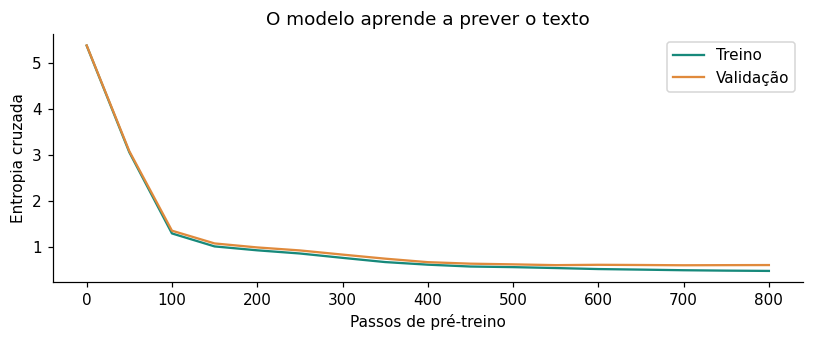

In [ ]:
def treinar(modelo, proximo_lote, passos, lr_max, aquecimento=50, avaliar=None, avaliar_cada=50):
    """O mesmo laço serve para pre-treino e SFT: só muda o que proximo_lote() devolve."""
    otimizador = Adam(modelo.p)
    historico = {"passo": [], "perda_lote": []}
    for passo in range(passos + 1):
        if avaliar is not None and (passo % avaliar_cada == 0 or passo == passos):
            historico["passo"].append(passo)
            for nome, valor in avaliar(modelo).items():
                historico.setdefault(nome, []).append(valor)
        if passo == passos:
            break
        X, Y, M = proximo_lote()                                    # 1. um lote
        perda, grads = perda_e_gradiente(modelo, X, Y, M)           # 2. previsão, perda e gradiente
        otimizador.passo(modelo.p, grads, taxa(passo, passos, lr_max, aquecimento))  # 3. atualização
        historico["perda_lote"].append(perda)
    return historico

T = 64
val_pt = janelas_fixas(ids_val, T)                               # trechos de validação, sempre os mesmos
tr_pt = tuple(a[:len(val_pt[0])] for a in janelas_fixas(ids_treino, T))
modelo_base = MiniGPT(len(tok.vocab), contexto=T, d=64, camadas=2, cabecas=4, semente=0)
print(f"Parâmetros: {modelo_base.n_params()}")

inicio = time.time()
hist_pt = treinar(modelo_base, lotes_de_texto(ids_treino, 32, T, np.random.default_rng(0)), 800, 3e-3, 100,
                  avaliar=lambda m: {"treino": perda_media(m, *tr_pt), "val": perda_media(m, *val_pt)},
                  avaliar_cada=50)
print(f"Pré-treino em {time.time() - inicio:.0f} s | perda de validação: {hist_pt['val'][0]:.2f} → {hist_pt['val'][-1]:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(hist_pt["passo"], hist_pt["treino"], color=TEAL, label="Treino")
ax.plot(hist_pt["passo"], hist_pt["val"], color=AMBER, label="Validação")
ax.set(xlabel="Passos de pré-treino", ylabel="Entropia cruzada", title="O modelo aprende a prever o texto")
ax.legend()
plt.tight_layout()
plt.show()

### O que o modelo base já consegue fazer?

Compare duas entradas sobre a Noruega: completar uma frase e continuar uma pergunta. A geração escolhe sempre o token mais provável (*greedy decoding*), até o limite definido no código.

Completar `A capital da Noruega é` com `Oslo` mostra sucesso **nessa forma de consultar o fato**. Na primeira pergunta ele conseguiu acertar, mas pelo corpus possuir perguntas sem respostas, ao perguntar "Qual é a capital da Noruega" ele seguiu com outra pergunta, apenas completando o proximo token sem realmente responder a pergunta.

In [ ]:
def continuar(modelo, texto, n=24):
    return tok.decodificar(gerar(modelo, [tok.codificar(texto)], n)[0])

print("1. 'A capital da Noruega é' →", repr(continuar(modelo_base, "<|endoftext|>A capital da Noruega é", 2)))
print("2. 'Qual é a capital da Noruega?' →", repr(continuar(modelo_base, "<|endoftext|>Qual é a capital da Noruega?\n", 20)))
print(f"\nO modelo base completa corretamente {completar_fatos(modelo_base, tok, PAISES):.0%} das {3 * len(PAISES)} frases de fato.")

1. 'A capital da Noruega é' → 'Oslo.'
2. 'Qual é a capital da Noruega?' → '2. Qual é a capital da Coreia do Sul?\n3. Qual é a capital da Coreia'

O modelo base completa corretamente 100% das 126 frases de fato.


## 3. Preparar demonstrações de instruções

Aqui geramos várias conversas para criar os dados que vão ser utilizados para ensinar o modelo a seguir instruções, tendo como objetivo que ele entenda a lógica/padrões das instruções.

Cada conversa contém `system` (orientação geral), `user` (pedido) e `assistant` (resposta desejada). Cerca de metade inclui um segundo pedido, que exige consultar o histórico para ensinar o modelo a usá-lo.

Usamos 25 países nas **conversas de SFT** e reservamos 17 para avaliar perguntas. Esses 17 já aparecem no pré-treino e voltarão a aparecer no **replay de texto** durante o ajuste. É importante entender a diferença, pois no finetuning não ensinamos muita coisa nova ao modelo e sim fazemos ele priorizar o que escolhemos no benchmark com base no que ele ja sabe, então não tem problema os dados aparecerem no pré treinamento.


In [ ]:
#@title Conversas: perguntas em 7 formas, respostas e sorteio dos dados (execute; leitura opcional)
def dividir_paises(semente=7, fracao_fora=0.4):
    """Em cada continente, ~40% dos países ficam FORA do ajuste: servem para testar
    se o modelo responde sobre países sem demonstrações de conversa."""
    rng = np.random.default_rng(semente)
    fora = []
    for cont in sorted({p[6] for p in PAISES}):
        grupo = [p for p in PAISES if p[6] == cont]
        idx = rng.permutation(len(grupo))
        fora += [grupo[i] for i in idx[:round(fracao_fora * len(grupo))]]
    return [p for p in PAISES if p not in fora], fora


def conversa(pais, rel, forma, seguinte=None, resposta=None):
    """Uma conversa no formato de mensagens (como nas APIs de chat)."""
    msgs = [{"role": "system", "content": SISTEMA},
            {"role": "user", "content": preencher(PERGUNTAS[rel][forma], pais)},
            {"role": "assistant", "content": resposta or preencher(RESPOSTA[rel], pais)}]
    if seguinte:
        msgs += [{"role": "user", "content": SEGUIMENTO[seguinte]},
                 {"role": "assistant", "content": preencher(RESPOSTA[seguinte], pais)}]
    return msgs


def dados_de_instrucao(paises, n, semente=0, formas=(0, 1, 2, 3, 4), pesos=(1, 1, 1),
                       dois_turnos=0.5, erradas=0.0):
    """n conversas sorteadas. Cada sorteio usa um número uniforme, para que mudar
    uma opção (formas, pesos, erradas) não mude os outros sorteios."""
    rng = np.random.default_rng(semente)
    acum = np.cumsum(pesos) / np.sum(pesos)
    coluna = {"capital": 4, "lingua": 5, "continente": 6}
    dados = []
    for _ in range(n):
        u = rng.random(7)
        pais = paises[int(u[0] * len(paises))]
        rel = RELACOES[int(np.searchsorted(acum, u[1], side="right"))]
        forma = formas[int(u[2] * len(formas))]
        outras = [r for r in RELACOES if r != rel]
        seguinte = outras[int(u[4] * 2)] if u[3] < dois_turnos else None
        resposta = None
        if u[5] < erradas:                      # resposta errada: o fato de outro país
            c = coluna[rel]
            candidatos = [q for q in paises if q[c] != pais[c]]
            falso = list(pais)
            falso[c] = candidatos[int(u[6] * len(candidatos))][c]
            resposta = preencher(RESPOSTA[rel], falso)
        dados.append(conversa(pais, rel, forma, seguinte, resposta))
    return dados

dentro, fora = dividir_paises()
print(f"No ajuste: {len(dentro)} países | fora do ajuste: {len(fora)}")
print("Fora:", ", ".join(p[0] for p in fora))

conversas = dados_de_instrucao(dentro, 600, semente=1)
exemplo = next(c for c in conversas if len(c) == 5)
print(f"\n{len(conversas)} conversas, {sum(len(c) == 5 for c in conversas)} com dois turnos. Uma delas:")
for m in exemplo:
    print(f"  {m['role']:>9}: {m['content']}")

No ajuste: 25 países | fora do ajuste: 17
Fora: México, Brasil, Equador, Uruguai, Itália, Noruega, Hungria, Romênia, Croácia, França, Nova Zelândia, Argélia, Tunísia, Japão, Iraque, Malásia, Vietnã

600 conversas, 319 com dois turnos. Uma delas:
     system: Responda em uma frase.
       user: Qual é a língua mais falada da Espanha?
  assistant: Na Espanha, fala-se espanhol.
       user: E a capital?
  assistant: A capital da Espanha é Madri.


## 4. O que entra no modelo e o que entra na loss?

Como o modelo aprende com a conversa
Primeiro, transformamos as mensagens em uma sequência de texto com marcadores que identificam quem está falando. Essa organização é o chat template.
Durante o treinamento, mostramos o pedido e a resposta correta. Calculamos o erro nas previsões dos tokens da resposta do assistant, incluindo o marcador que indica seu fim. O pedido serve como contexto.
Essa escolha de quais posições entram no cálculo do erro é chamada de máscara da loss.

<|im_start|>system
Responda em uma frase.<|im_end|>
<|im_start|>user
Qual é a língua mais falada da Espanha?<|im_end|>
<|im_start|>assistant
Na Espanha, fala-se espanhol.<|im_end|>
<|im_start|>user
E a capital?<|im_end|>
<|im_start|>assistant
A capital da Espanha é Madri.<|im_end|>

---- na hora de gerar, a conversa termina assim:
<|im_start|>system
Responda em uma frase.<|im_end|>
<|im_start|>user
Qual é a língua mais falada da Espanha?<|im_end|>
<|im_start|>assistant



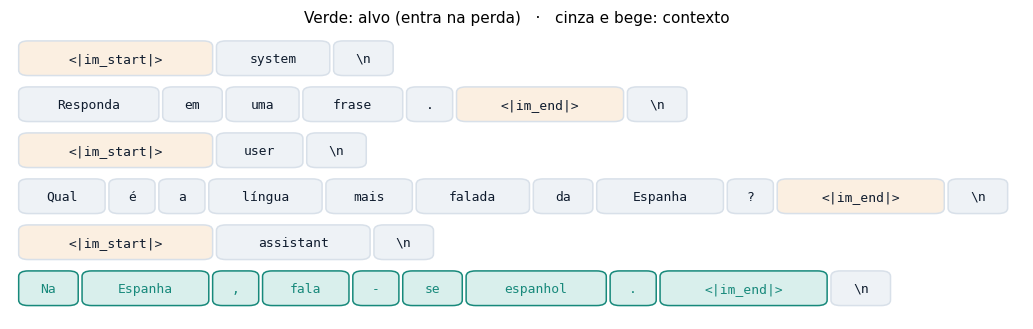

Nos 600 exemplos: 7627 de 27895 tokens são alvo (27%).

Último token lido | Próximo alvo Y | M
'<|im_start|>'     | 'assistant'    | 0
'assistant'        | '\n'           | 0
'\n'               | 'Na'           | 1
'Na'               | 'Espanha'      | 1
'Espanha'          | ','            | 1
','                | 'fala'         | 1


In [ ]:
def aplicar_template(mensagens, abrir_resposta=False):
    """ChatML, o formato usado por modelos como o Qwen."""
    texto = "".join("<|im_start|>%s\n%s<|im_end|>\n" % (m["role"], m["content"]) for m in mensagens)
    if abrir_resposta:
        texto += "<|im_start|>assistant\n"
    return texto


print(aplicar_template(exemplo))
print("---- na hora de gerar, a conversa termina assim:")
print(aplicar_template(exemplo[:2], abrir_resposta=True))

def tokens_e_alvos(tok, mensagens, modo="resposta"):
    """Tokens da conversa e máscara de alvos.
    modo="resposta": só o texto do assistant e o <|im_end|> que o encerra contam na perda;
    modo="sem_fim":  igual, mas sem o <|im_end|>;
    modo="tudo":     todos os tokens contam (como no pre-treino)."""
    ids, alvo = [], []
    for m in mensagens:
        cabeca = tok.codificar("<|im_start|>%s\n" % m["role"])
        corpo = tok.codificar(m["content"])
        fim = tok.codificar("<|im_end|>")
        quebra = tok.codificar("\n")
        resp = m["role"] == "assistant"
        ids += cabeca + corpo + fim + quebra
        if modo == "tudo":
            alvo += [1] * (len(cabeca) + len(corpo) + len(fim) + len(quebra))
        else:
            alvo += [0] * len(cabeca) + [int(resp)] * len(corpo)
            alvo += [int(resp and modo == "resposta")] * len(fim) + [0] * len(quebra)
    return np.array(ids), np.array(alvo, np.float32)


ids, alvos = tokens_e_alvos(tok, exemplo[:3])
fig, ax = plt.subplots(figsize=(9.5, 3.1))
x, y, xmax = 0.0, 0.0, 0.0
for t, a in zip([tok.vocab[i] for i in ids], alvos):
    rotulo = "\\n" if t == "\n" else t
    larg = 0.14 * len(rotulo) + 0.3
    cor = "#D9EFEC" if a else ("#FBEFE1" if t.startswith("<|") else "#EEF2F6")
    ax.add_patch(FancyBboxPatch((x, y - 0.3), larg, 0.6, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor, ec=TEAL if a else "#D8E0E9"))
    ax.text(x + larg / 2, y, rotulo, ha="center", va="center", family="monospace", fontsize=8.5,
            color=TEAL if a else INK)
    x += larg + 0.08
    xmax = max(xmax, x)
    if t == "\n":
        x, y = 0.0, y - 0.85
ax.set_xlim(-0.1, xmax + 0.1); ax.set_ylim(y + 0.3, 0.5); ax.axis("off")
ax.set_title("Verde: alvo (entra na perda)   ·   cinza e bege: contexto", fontsize=10)
plt.tight_layout()
plt.show()

exemplos = [tokens_e_alvos(tok, c) for c in conversas]
n_tok, n_alvo = sum(len(i) for i, _ in exemplos), sum(a.sum() for _, a in exemplos)
print(f"Nos {len(exemplos)} exemplos: {int(n_alvo)} de {n_tok} tokens são alvo ({n_alvo / n_tok:.0%}).")
primeiro = int(np.flatnonzero(alvos)[0])
print("\nÚltimo token lido | Próximo alvo Y | M")
for j in range(primeiro-2, min(primeiro+4,len(ids))):
    print(f"{tok.vocab[ids[j-1]]!r:18s} | {tok.vocab[ids[j]]!r:14s} | {int(alvos[j])}")

## 5. Ajustar os pesos com SFT e replay

Partimos de uma **cópia do modelo base** e de um novo estado do Adam. Na geração anterior só produzimos texto; agora atualizamos os pesos com respostas de exemplo.

O lote tem 28 conversas com perda nas respostas e 4 janelas do texto de pré-treino, com perda em todos os seus tokens. Essa mistura é **replay**: quando fazemos com que o modelo reveja algum dos trechos do pré treinamento, evitamos o catastrophic forgetting

**Observe as duas curvas:** uma mede a perda nas respostas em conversas reservadas; a outra mede a perda no texto de pré-treino. É interessante vermos que o modelo aprende com o SFT sem degradar no que ele ja sabia antes, isso é bem importante.

In [ ]:
#@title Lotes de conversas, com padding e replay (execute; leitura opcional)
def lotes_de_conversas(exemplos, B, rng, pad, texto_ids=None, linhas_texto=0):
    """SFT: cada linha do lote é uma conversa, completada com <|pad|> (que nunca é alvo).
    linhas_texto > 0 mistura janelas do texto de pre-treino no lote (replay)."""
    ordem, pos = rng.permutation(len(exemplos)), 0
    def proximo():
        nonlocal ordem, pos
        n = min(B - linhas_texto, len(exemplos))
        if pos + n > len(exemplos):
            ordem, pos = rng.permutation(len(exemplos)), 0
        escolha = ordem[pos:pos + n]
        pos += n
        T = max(len(exemplos[i][0]) for i in escolha) - 1
        X = np.full((n + linhas_texto, T), pad)
        Y = np.full((n + linhas_texto, T), pad)
        M = np.zeros((n + linhas_texto, T), np.float32)
        for j, i in enumerate(escolha):
            ids, alvo = exemplos[i]
            X[j, :len(ids) - 1], Y[j, :len(ids) - 1], M[j, :len(ids) - 1] = ids[:-1], ids[1:], alvo[1:]
        for j in range(n, n + linhas_texto):
            ini = rng.integers(0, len(texto_ids) - T - 1)
            X[j], Y[j], M[j] = texto_ids[ini:ini + T], texto_ids[ini + 1:ini + T + 1], 1.0
        return X, Y, M
    return proximo


def conversas_fixas(exemplos, pad):
    """Um único lote com todas as conversas (para medir a perda sempre no mesmo conjunto)."""
    L = max(len(i) for i, _ in exemplos)
    X = np.full((len(exemplos), L - 1), pad)
    Y = X.copy()
    M = np.zeros(X.shape, np.float32)
    for j, (i, a) in enumerate(exemplos):
        X[j, :len(i) - 1], Y[j, :len(i) - 1], M[j, :len(i) - 1] = i[:-1], i[1:], a[1:]
    return X, Y, M

def ajustar(exemplos, passos=300, lr=1e-3, linhas_texto=4, semente=3, modelo=None, ids_replay=None, curvas=False):
    # Copia o modelo base e faz o SFT. linhas_texto: quantas das 32 linhas são texto de pré-treino (replay).
    m = copy.deepcopy(modelo or modelo_base)
    avaliar = None
    if curvas:
        avaliar = lambda mm: {"sft_val": perda_media(mm, *val_sft), "pt_val": perda_media(mm, *val_pt)}
    hist = treinar(m, lotes_de_conversas(exemplos, 32, np.random.default_rng(semente), PAD,
                                         ids_treino if ids_replay is None else ids_replay, linhas_texto),
                   passos, lr, 20, avaliar=avaliar, avaliar_cada=25)
    return m, hist

Primeiro lote: 388 alvos de conversa e 248 de replay
Replay: 39.0% dos alvos desse lote
SFT em 46 s
Perda nas respostas (países de fora): 5.30 → 0.03
Perda no texto de pré-treino:          0.61 → 0.61


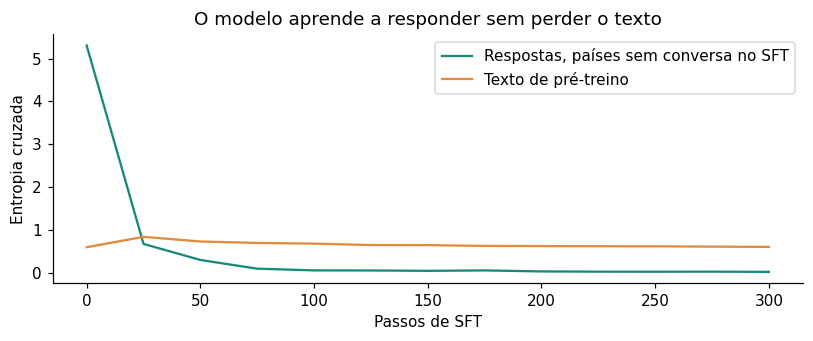

In [ ]:
val_sft = conversas_fixas([tokens_e_alvos(tok, c) for c in dados_de_instrucao(fora, 200, semente=2)], PAD)



CONFIG_SFT = dict(passos=300, lr=1e-3, linhas_texto=4, semente=3)
_, _, mascara_lote = lotes_de_conversas(exemplos, 32, np.random.default_rng(3), PAD, ids_treino, 4)()
alvos_conversa, alvos_replay = int(mascara_lote[:28].sum()), int(mascara_lote[28:].sum())
print(f"Primeiro lote: {alvos_conversa} alvos de conversa e {alvos_replay} de replay")
print(f"Replay: {alvos_replay / mascara_lote.sum():.1%} dos alvos desse lote")

inicio = time.time()
modelo_sft, hist_sft = ajustar(exemplos, curvas=True, **CONFIG_SFT)
print(f"SFT em {time.time() - inicio:.0f} s")
print(f"Perda nas respostas (países de fora): {hist_sft['sft_val'][0]:.2f} → {hist_sft['sft_val'][-1]:.2f}")
print(f"Perda no texto de pré-treino:          {hist_sft['pt_val'][0]:.2f} → {hist_sft['pt_val'][-1]:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(hist_sft["passo"], hist_sft["sft_val"], color=TEAL, label="Respostas, países sem conversa no SFT")
ax.plot(hist_sft["passo"], hist_sft["pt_val"], color=AMBER, label="Texto de pré-treino")
ax.set(xlabel="Passos de SFT", ylabel="Entropia cruzada", title="O modelo aprende a responder sem perder o texto")
ax.legend()
plt.tight_layout()
plt.show()

## 6. O que mudou depois do SFT?

Agora vamos comparar o modelo base com o modelo ajustado. Fazemos os mesmos pedidos aos dois e observamos as respostas. Nesta etapa, não há treinamento: os pesos ficam fixos.

Queremos descobrir se o modelo aprendeu a responder e se consegue usar esse comportamento em situações diferentes das conversas de treinamento.

### Quais perguntas fazemos?

| Grupo | O que queremos verificar |
|---|---|
| **Países do ajuste** | Ele responde sobre os países usados nas conversas de treinamento? |
| **Países de fora** | Ele responde sobre países que não tiveram exemplos de conversa? |
| **Formas novas de pedido** | Ele responde quando mudamos o jeito de escrever a pergunta? |
| **Segundo turno** | Ele usa o histórico para entender um pedido como “E a capital?”? |

Os países de fora já apareciam no pré-treino e também podem aparecer nos textos de replay. O que reservamos foram as conversas sobre eles.

No teste de segundo turno, fornecemos um histórico com uma resposta anterior correta e pedimos que o modelo continue. Por exemplo:

- user: Em que continente fica a Noruega?
- assistant: A Noruega fica na Europa.
- user: E a capital?

A resposta avaliada é a continuação desse histórico.

### Quando contamos um acerto?

A resposta precisa ser igual à referência e terminar com o marcador de fim. Também mostramos separadamente quantas respostas terminam corretamente, pois saber parar não significa acertar o conteúdo.

Esse critério é exigente: uma resposta com o fato correto, mas escrita de outra forma, pode não receber acerto.

### E o que ele já fazia antes?

Além das perguntas, verificamos se o modelo ainda:

- completa frases como “A capital da Noruega é…”;
- prevê bem os textos reservados do pré-treino.

Assim, conseguimos observar tanto a melhora nas respostas quanto possíveis perdas de capacidades anteriores. Leia as medidas em conjunto: uma melhora no formato de conversa não garante que todo o restante foi preservado.

In [ ]:
#@title Casos de teste, geração das respostas e acerto exato (execute; leitura opcional)
def casos_de_teste(paises, formas=(0,), rels=RELACOES, seguimento=False):
    """Pares (mensagens sem a última resposta, resposta esperada, rótulos)."""
    casos = []
    for pais in paises:
        for rel in rels:
            if seguimento:
                for seg in (r for r in RELACOES if r != rel):
                    msgs = conversa(pais, rel, 0, seg)[:-1]
                    casos.append((msgs, preencher(RESPOSTA[seg], pais), (pais[0], seg, "seguimento")))
            else:
                for f in formas:
                    msgs = conversa(pais, rel, f)[:-1]
                    casos.append((msgs, preencher(RESPOSTA[rel], pais), (pais[0], rel, f)))
    return casos


def responder(modelo, tok, conversas, template=aplicar_template, max_novos=16):
    fim = tok.id["<|im_end|>"]
    prompts = [tok.codificar(template(m, abrir_resposta=True)) for m in conversas]
    saidas = gerar(modelo, prompts, max_novos, parar=fim)
    return [(s[:-1] if s and s[-1] == fim else s, bool(s) and s[-1] == fim) for s in saidas]


def acuracia(modelo, tok, casos, template=aplicar_template):
    """Acerto exato: a resposta inteira igual à esperada e terminada com <|im_end|>."""
    saidas = responder(modelo, tok, [c[0] for c in casos], template)
    certo = [parou and ids == tok.codificar(c[1]) for (ids, parou), c in zip(saidas, casos)]
    return float(np.mean(certo)), float(np.mean([p for _, p in saidas])), saidas

In [ ]:
from html import escape

try:
    from IPython.display import HTML, display
except ImportError:
    HTML = display = None


# Exibe tabelas no notebook e texto simples em outros ambientes.
def mostrar_resultados(titulo, colunas, linhas, explicacao):
    def texto(valor):
        return escape(str(valor)).replace("\n", "<br>")

    cabecalho = "".join(
        f"<th>{texto(coluna)}</th>"
        for coluna in colunas
    )

    corpo = "".join(
        "<tr>"
        + "".join(f"<td>{texto(valor)}</td>" for valor in linha)
        + "</tr>"
        for linha in linhas
    )

    tabela = (
        f"<section>"
        f"<h3>{texto(titulo)}</h3>"
        f"<p>{texto(explicacao)}</p>"
        f"<table>"
        f"<thead><tr>{cabecalho}</tr></thead>"
        f"<tbody>{corpo}</tbody>"
        f"</table>"
        f"</section>"
    )

    if display is not None:
        display(HTML(tabela))
    else:
        print("\n" + titulo)
        print(explicacao)
        print(" | ".join(colunas))
        for linha in linhas:
            print(
                " | ".join(
                    str(valor).replace("\n", " / ")
                    for valor in linha
                )
            )


def resultado(taxa, quantidade):
    percentual = f"{100 * taxa:.1f}".replace(".", ",")
    acertos = round(taxa * quantidade)
    return f"{acertos}/{quantidade} ({percentual}%)"


# Os grupos de perguntas permanecem iguais aos do experimento original.
CASOS = {
    "Países do ajuste": casos_de_teste(
        dentro, formas=(0, 1, 2, 3, 4)
    ),
    "Países de fora": casos_de_teste(
        fora, formas=(0, 1, 2, 3, 4)
    ),
    "Formas novas de pedido": casos_de_teste(
        fora, formas=(5, 6)
    ),
    "Segundo turno": casos_de_teste(
        fora, seguimento=True
    ),
}


def medir(modelo):
    medidas = {}

    for grupo, casos in CASOS.items():
        acerto, parada, _ = acuracia(modelo, tok, casos)
        medidas[grupo] = acerto
        medidas["para: " + grupo] = parada

    medidas["Completa fatos (texto corrido)"] = completar_fatos(
        modelo, tok, PAISES
    )
    medidas["Perda no texto de pré-treino"] = perda_media(
        modelo, *val_pt
    )

    return medidas


antes = medir(modelo_base)
depois = medir(modelo_sft)


# 1. Respostas aos pedidos
nomes = {
    "Países do ajuste":
        "Países usados nas conversas de treino",
    "Países de fora":
        "Países sem conversas de treino",
    "Formas novas de pedido":
        "Duas formas de perguntar reservadas",
    "Segundo turno":
        "Perguntas que dependem de um histórico correto",
}

mostrar_resultados(
    "1. O modelo passou a responder aos pedidos?",
    ["Perguntas avaliadas", "Antes do SFT", "Depois do SFT"],
    [
        (
            nomes[grupo],
            resultado(antes[grupo], len(casos)),
            resultado(depois[grupo], len(casos)),
        )
        for grupo, casos in CASOS.items()
    ],
    (
        "Cada célula mostra acertos/total e percentual. "
        "O acerto exige a resposta inteira igual à referência "
        "e o marcador de fim."
    ),
)


# 2. Parada e retenção das capacidades anteriores
grupo = "Países de fora"
chave_fatos = "Completa fatos (texto corrido)"
chave_perda = "Perda no texto de pré-treino"
total_fatos = 3 * len(PAISES)

mostrar_resultados(
    "2. O que aconteceu com a parada e com o texto antigo?",
    ["Medida", "Antes do SFT", "Depois do SFT", "Como ler"],
    [
        (
            "Encerra a resposta nos pedidos sobre países sem conversas de treino",
            resultado(antes["para: " + grupo], len(CASOS[grupo])),
            resultado(depois["para: " + grupo], len(CASOS[grupo])),
            "Produziu o marcador de fim. Isso sozinho não garante conteúdo correto.",
        ),
        (
            "Completa fatos em frases, sem formato de chat",
            resultado(antes[chave_fatos], total_fatos),
            resultado(depois[chave_fatos], total_fatos),
            "Mais acertos indicam melhor completamento nessas frases.",
        ),
        (
            "Perda na previsão do texto de pré-treino",
            f"{antes[chave_perda]:.2f}".replace(".", ","),
            f"{depois[chave_perda]:.2f}".replace(".", ","),
            "É um erro médio, não um percentual. Menor é melhor.",
        ),
    ],
    (
        "A parada avalia o comportamento no chat. "
        "As outras duas linhas acompanham capacidades "
        "exercitadas no pré-treino."
    ),
)


# 3. Exemplos concretos, incluindo o histórico do segundo turno
noruega = next(pais for pais in fora if pais[0] == "Noruega")

exemplos_noruega = [
    (
        "Pedido direto",
        conversa(noruega, "capital", 0)[:-1],
    ),
    (
        "Outra forma de perguntar",
        conversa(noruega, "capital", 5)[:-1],
    ),
    (
        "Pedido que depende do histórico",
        conversa(noruega, "capital", 0, "continente")[:-1],
    ),
]

linhas = []

for situacao, mensagens in exemplos_noruega:
    resposta, terminou = responder(
        modelo_sft, tok, [mensagens]
    )[0]

    contexto = "\n".join(
        (
            "Resposta anterior fornecida: "
            if mensagem["role"] == "assistant"
            else "Pessoa: "
        )
        + mensagem["content"]
        for mensagem in mensagens
        if mensagem["role"] != "system"
    )

    linhas.append(
        (
            situacao,
            contexto,
            tok.decodificar(resposta),
            "Sim" if terminou else "Não",
        )
    )

mostrar_resultados(
    "3. Exemplos: respostas sobre a Noruega depois do SFT",
    ["Situação", "O modelo recebeu", "Resposta gerada", "Encerrou?"],
    linhas,
    (
        "A Noruega ficou fora das conversas de treino. "
        "No último exemplo, o avaliador fornece a resposta anterior "
        "correta; só a última resposta é gerada e avaliada."
    ),
)


# 4. Exemplos de respostas quando a informação foi omitida
linhas = []

for pais in SEM_CAPITAL[:5]:
    pedido = conversa(pais, "capital", 0)[:-1]

    resposta, terminou = responder(
        modelo_sft, tok, [pedido]
    )[0]

    linhas.append(
        (
            pedido[-1]["content"],
            tok.decodificar(resposta),
            "Sim" if terminou else "Não",
        )
    )

mostrar_resultados(
    "4. E quando a capital não foi ensinada nos textos?",
    ["Pergunta", "Resposta gerada depois do SFT", "Encerrou?"],
    linhas,
    (
        "As capitais destes países foram omitidas do corpus. "
        "Observe que terminar uma resposta no formato aprendido "
        "não garante que ela tenha apoio nos dados."
    ),
)

Perguntas avaliadas,Antes do SFT,Depois do SFT
Países usados nas conversas de treino,"0/375 (0,0%)","375/375 (100,0%)"
Países sem conversas de treino,"0/255 (0,0%)","248/255 (97,3%)"
Duas formas de perguntar reservadas,"0/102 (0,0%)","88/102 (86,3%)"
Perguntas que dependem de um histórico correto,"0/102 (0,0%)","95/102 (93,1%)"


Medida,Antes do SFT,Depois do SFT,Como ler
Encerra a resposta nos pedidos sobre países sem conversas de treino,"0/255 (0,0%)","255/255 (100,0%)",Produziu o marcador de fim. Isso sozinho não garante conteúdo correto.
"Completa fatos em frases, sem formato de chat","126/126 (100,0%)","126/126 (100,0%)",Mais acertos indicam melhor completamento nessas frases.
Perda na previsão do texto de pré-treino,"0,61","0,61","É um erro médio, não um percentual. Menor é melhor."


Situação,O modelo recebeu,Resposta gerada,Encerrou?
Pedido direto,Pessoa: Qual é a capital da Noruega?,A capital da Noruega é Oslo.,Sim
Outra forma de perguntar,Pessoa: Noruega tem qual capital?,A capital da Noruega é Oslo.,Sim
Pedido que depende do histórico,Pessoa: Qual é a capital da Noruega?Resposta anterior fornecida: A capital da Noruega é Oslo.Pessoa: E o continente?,A Noruega fica na Europa.,Sim


Pergunta,Resposta gerada depois do SFT,Encerrou?
Qual é a capital da Mongólia?,A capital da Mongólia é Bangkok.,Sim
Qual é a capital do Nepal?,A capital do Nepal é Ottawa.,Sim
Qual é a capital da Islândia?,A Islândia fica na Europa.,Sim
Qual é a capital da Bolívia?,A capital da Bolívia é um país da América do Sul.,Sim
Qual é a capital da Tanzânia?,A capital da Tanzânia é Pequim.,Sim


**O que podemos concluir:** o ajuste mudou o comportamento em prompts de chat e permitiu responder a várias perguntas sem demonstrações de conversa para aqueles países. Contudo, os fatos desses países também estavam disponíveis no replay; não isolamos “só o formato mudou”. O SFT pode ensinar fatos e habilidades quando suas demonstrações os contêm.

As capitais omitidas tornam visível outro limite: o modelo pode produzir uma resposta no formato aprendido, mas sem apoio nos dados. A geração aqui é gulosa; não medimos confiança ou calibração. Os exemplos exibidos não estimam uma taxa geral de alucinação.

Acertar os exemplos do ajuste pode envolver memorização. Acertar casos reservados dentro deste mundo reduz essa preocupação, mas não demonstra capacidade geral de seguir qualquer instrução.

## 7. O que pode se perder durante o ajuste?

Treinamos outra **cópia do mesmo modelo base**, agora sem replay, com a mesma taxa e o mesmo número de passos. Os dois modelos de SFT são ramos separados; o segundo não continua o primeiro.

Esta comparação mede **duas receitas**: 28 conversas + 4 janelas de texto por passo contra 32 conversas. A exposição a conversas e o consumo do sorteio também mudam. Ela mostra a diferença observada, sem isolar o replay sob orçamento e sequência de conversas idênticos.

**Antes de olhar:** se ambos acertarem os países usados nas conversas, qual outra medida revelaria uma perda de capacidade?

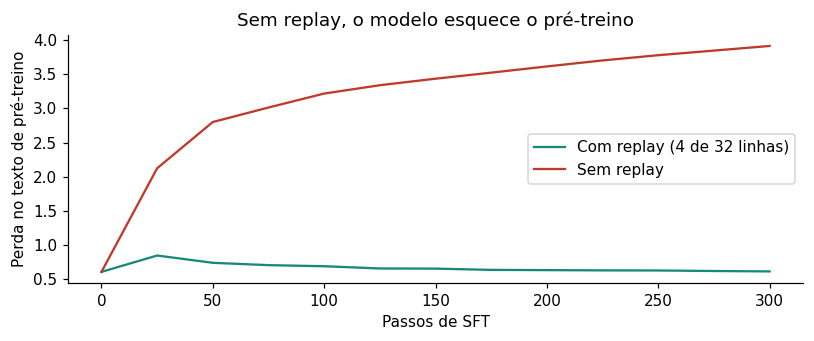

                                    com replay  sem replay
Países do ajuste                          100%        100%
Países de fora                             97%         35%
Completa fatos (texto corrido)            100%         82%
Perda no texto de pré-treino              0.61        3.92

Sem replay, 'Qual é a capital da Noruega?' → A capital da Tailândia é Bangkok.


In [ ]:
modelo_sem_replay, hist_sem = ajustar(exemplos, linhas_texto=0, curvas=True)
sem = medir(modelo_sem_replay)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(hist_sft["passo"], hist_sft["pt_val"], color=TEAL, label="Com replay (4 de 32 linhas)")
ax.plot(hist_sem["passo"], hist_sem["pt_val"], color=RED, label="Sem replay")
ax.set(xlabel="Passos de SFT", ylabel="Perda no texto de pré-treino", title="Sem replay, o modelo esquece o pré-treino")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'':34s}{'com replay':>12s}{'sem replay':>12s}")
for k in ["Países do ajuste", "Países de fora", "Completa fatos (texto corrido)"]:
    print(f"{k:34s}{depois[k]:>12.0%}{sem[k]:>12.0%}")
k = "Perda no texto de pré-treino"
print(f"{k:34s}{depois[k]:>12.2f}{sem[k]:>12.2f}")
resp, _ = responder(modelo_sem_replay, tok, [conversa(noruega, "capital", 0)[:-1]])[0]
print("\nSem replay, 'Qual é a capital da Noruega?' →", tok.decodificar(resp))

**Interpretação:** sem replay, o desempenho nas conversas do ajuste continua alto, mas a previsão do texto antigo e a conclusão de fatos pioram. Essa regressão é evidência de esquecimento de comportamentos anteriores neste experimento, chamado *catastrophic forgetting*.

A perda maior no texto antigo não significa que todos os fatos foram apagados. O comportamento de saída também pode ter mudado. Usamos mais de uma medida para acompanhar a regressão. Acerto de 100% nas conversas do ajuste, sozinho, também não prova memorização literal.
